# Lab 3 — Nhận dạng lệnh tiếng Việt bằng HMM

Notebook triển khai các phần theo đề: MFCC 39 chiều (13 MFCC tĩnh + delta + delta-delta), 5 whole-word HMM trái sang phải với Gaussian, huấn luyện Baum–Welch, Viterbi, đánh giá, DTW baseline và bigram re-ranking.

> Dataset hiện tại là eSpeak TTS tổng hợp (xem `dataset/README.txt`), không phải ghi âm người. Kết quả đánh giá chỉ phản ánh starter set nhỏ này.


## Task 0 — Cài đặt môi trường
Chạy cell cài đặt bên dưới trước khi chạy imports. Cell này cài dependencies từ `requirements.txt` vào đúng môi trường Python của kernel hiện tại. Sau khi cài xong, nếu Jupyter yêu cầu thì restart kernel rồi chạy lại từ đầu.


In [1]:
import importlib.util, subprocess, sys
required = {'numpy': 'numpy', 'scipy': 'scipy', 'matplotlib': 'matplotlib', 'pandas': 'pandas', 'sklearn': 'scikit-learn', 'hmmlearn': 'hmmlearn', 'soundfile': 'soundfile'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing packages:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', 'requirements.txt'])
else:
    print('All required packages are already available in this kernel.')


All required packages are already available in this kernel.


## Task 1 — Imports, đường dẫn tương đối và đọc metadata
Đường dẫn dataset được suy ra từ vị trí notebook; khi clone repo, đặt `dataset/` cạnh notebook. Có thể ghi đè bằng biến môi trường `LAB3_DATA_DIR`.


In [2]:
from pathlib import Path
import os, time, warnings
import joblib
import numpy as np
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from hmmlearn.hmm import GaussianHMM

SEED = 42
np.random.seed(SEED)
NOTEBOOK_DIR = Path.cwd()
OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
MODEL_DIR = NOTEBOOK_DIR / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
# Cho phép override khi chạy ở vị trí khác, mặc định là thư mục dataset cạnh notebook.
DATA_DIR = Path(os.environ.get("LAB3_DATA_DIR", NOTEBOOK_DIR / "dataset")).expanduser().resolve()
METADATA_PATH = DATA_DIR / "metadata.csv"
assert METADATA_PATH.exists(), f"Không thấy {METADATA_PATH}. Đặt dataset cạnh notebook hoặc đặt LAB3_DATA_DIR."
metadata = pd.read_csv(METADATA_PATH)
LABELS = sorted(metadata["label_code"].dropna().unique().tolist())
DISPLAY_NAMES = dict(metadata[["label_code", "label"]].drop_duplicates().values)
print("Dataset:", DATA_DIR)
print("Classes:", {k: DISPLAY_NAMES[k] for k in LABELS})
print(metadata.groupby(["split", "label_code"]).size().unstack(fill_value=0))


Dataset: C:\Users\HP\Downloads\Lab03\dataset
Classes: {'dong': 'đóng', 'dung': 'dừng', 'len': 'lên', 'mo': 'mở', 'xuong': 'xuống'}
label_code  dong  dung  len  mo  xuong
split                                 
test           2     2    2   2      2
train          6     6    6   6      6


## Task 2 — Kiểm tra WAV và trực quan hóa tín hiệu
Đề yêu cầu WAV mono, 16 kHz, PCM 16-bit và có khoảng lặng ở hai đầu. Cell này kiểm tra định dạng và phát/xem một mẫu.


mo_01.wav 16000 (22504,) int16
mo_02.wav 16000 (21447,) int16
mo_03.wav 16000 (20300,) int16


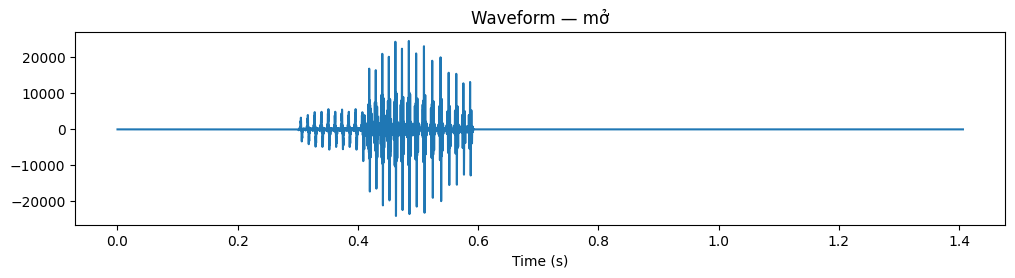

In [3]:
from IPython.display import Audio, display
from scipy.io import wavfile

def audio_path(row):
    # Ưu tiên split/filename theo metadata; không phụ thuộc thư mục theo lớp.
    return DATA_DIR / str(row["split"]) / str(row["filename"])

missing = [str(audio_path(r)) for _, r in metadata.iterrows() if not audio_path(r).exists()]
assert not missing, "Thiếu WAV: " + ", ".join(missing[:5])
for _, row in metadata.head(3).iterrows():
    sr, wav = wavfile.read(audio_path(row))
    print(row.filename, sr, wav.shape, wav.dtype)
row = metadata.iloc[0]
sr, wav = wavfile.read(audio_path(row))
plt.figure(figsize=(12, 2.5)); plt.plot(np.arange(len(wav))/sr, wav); plt.title(f"Waveform — {row.label}"); plt.xlabel("Time (s)"); plt.show()
display(Audio(wav, rate=sr))


## Task 3 — Trích xuất MFCC 39 chiều
Mỗi frame gồm 13 MFCC tĩnh, delta bậc một và delta bậc hai. Cắt khoảng lặng đầu/cuối bằng librosa.effects.trim. Chuẩn hóa MFCC theo thống kê toàn cục, chỉ tính trên train để tránh rò rỉ dữ liệu.


In [4]:
from scipy.fft import dct

N_MFCC = 13
N_FFT = 400       # 25 ms at 16 kHz
HOP_LENGTH = 160  # 10 ms
N_MELS = 40
SAMPLE_RATE = 16000

def _hz_to_mel(hz):
    return 2595.0 * np.log10(1.0 + np.asarray(hz) / 700.0)

def _mel_filterbank(sr=SAMPLE_RATE, n_fft=N_FFT, n_mels=N_MELS):
    mel_points = np.linspace(_hz_to_mel(0), _hz_to_mel(sr / 2), n_mels + 2)
    hz_points = 700.0 * (10.0 ** (mel_points / 2595.0) - 1.0)
    bins = np.floor((n_fft + 1) * hz_points / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float64)
    for m in range(1, n_mels + 1):
        left, center, right = bins[m - 1:m + 2]
        center = max(center, left + 1)
        right = max(right, center + 1)
        for k in range(max(0, left), min(center, bank.shape[1])):
            bank[m - 1, k] = (k - left) / (center - left)
        for k in range(max(0, center), min(right, bank.shape[1])):
            bank[m - 1, k] = (right - k) / (right - center)
    return bank

MEL_BANK = _mel_filterbank()
WINDOW = np.hamming(N_FFT)

def _delta(feat, width=2):
    # Regression delta with replicated edge frames.
    padded = np.pad(feat, ((width, width), (0, 0)), mode="edge")
    denom = 2 * sum(i * i for i in range(1, width + 1))
    out = np.zeros_like(feat)
    for i in range(1, width + 1):
        out += i * (padded[width + i:width + i + len(feat)] - padded[width - i:width - i + len(feat)])
    return out / denom

def extract_features(path):
    sr, audio = wavfile.read(path)
    if sr != SAMPLE_RATE:
        raise ValueError(f"Expected {SAMPLE_RATE} Hz audio, got {sr} Hz: {path}")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if np.issubdtype(audio.dtype, np.integer):
        y = audio.astype(np.float64) / max(abs(np.iinfo(audio.dtype).min), np.iinfo(audio.dtype).max)
    else:
        y = audio.astype(np.float64)
    # Trim low-energy leading/trailing silence with a peak-relative threshold.
    peak = np.max(np.abs(y)) if len(y) else 0.0
    active = np.flatnonzero(np.abs(y) > max(peak * 0.015, 1e-5))
    if len(active):
        y = y[active[0]:active[-1] + 1]
    if len(y) < N_FFT:
        y = np.pad(y, (0, N_FFT - len(y)))
    emphasized = np.append(y[0], y[1:] - 0.97 * y[:-1])
    padded = np.pad(emphasized, (N_FFT // 2, N_FFT // 2), mode="reflect")
    n_frames = 1 + (len(padded) - N_FFT) // HOP_LENGTH
    shape = (n_frames, N_FFT)
    strides = (padded.strides[0] * HOP_LENGTH, padded.strides[0])
    frames = np.lib.stride_tricks.as_strided(padded, shape=shape, strides=strides).copy()
    power = np.abs(np.fft.rfft(frames * WINDOW, n=N_FFT, axis=1)) ** 2
    mel_energy = np.maximum(power @ MEL_BANK.T, 1e-10)
    cepstra = dct(10.0 * np.log10(mel_energy), type=2, axis=1, norm="ortho")[:, :N_MFCC]
    delta = _delta(cepstra)
    delta2 = _delta(delta)
    return np.concatenate([cepstra, delta, delta2], axis=1).astype(np.float64)

features = {row.filename: extract_features(audio_path(row)) for _, row in metadata.iterrows()}
train_meta = metadata[metadata.split == "train"].reset_index(drop=True)
test_meta = metadata[metadata.split == "test"].reset_index(drop=True)
# Global CMVN (39 dims), stats computed on training frames only.
train_frames = np.concatenate([features[f] for f in train_meta.filename])
feat_mean = train_frames.mean(axis=0)
feat_std = train_frames.std(axis=0)
feat_std[feat_std < 1e-6] = 1.0
features = {k: (v - feat_mean) / feat_std for k, v in features.items()}
print("Feature shape example:", features[train_meta.filename.iloc[0]].shape)


Feature shape example: (29, 39)


## Task 4 — HMM: khởi tạo trái sang phải và huấn luyện Baum–Welch
`hmmlearn.GaussianHMM` thực hiện Baum–Welch trong bước `fit`. Khởi tạo phân đoạn chuỗi theo thời gian vào các state; chỉ cho phép self-loop hoặc chuyển sang state kế tiếp. Với corpus nhỏ, covariance đường chéo giảm nguy cơ ma trận covariance suy biến.


In [5]:
N_STATES = 5
N_ITER = 10
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

def make_left_right_hmm(n_states=N_STATES, covariance_type="diag", seed=SEED):
    model = GaussianHMM(n_components=n_states, covariance_type=covariance_type,
                        n_iter=N_ITER, tol=1e-3, random_state=seed,
                        min_covar=1e-3, verbose=False, init_params="")
    model.startprob_ = np.r_[1.0, np.zeros(n_states-1)]
    trans = np.zeros((n_states, n_states))
    for i in range(n_states):
        if i == n_states-1: trans[i, i] = 1.0
        else: trans[i, i], trans[i, i+1] = 0.6, 0.4
    model.transmat_ = trans
    return model

models, train_seconds = {}, {}
for label in LABELS:
    seqs = [features[r.filename] for _, r in train_meta[train_meta.label_code == label].iterrows()]
    X = np.concatenate(seqs)
    lengths = [len(s) for s in seqs]
    model = make_left_right_hmm()
    # Khởi tạo emission means bằng phân đoạn đều từ các utterance của lớp.
    chunks = [[] for _ in range(N_STATES)]
    for seq in seqs:
        bounds = np.linspace(0, len(seq), N_STATES+1, dtype=int)
        for st in range(N_STATES): chunks[st].append(seq[bounds[st]:max(bounds[st]+1,bounds[st+1])])
    model.means_ = np.vstack([np.concatenate(chunks[s]).mean(axis=0) for s in range(N_STATES)])
    model.covars_ = np.tile(np.maximum(X.var(axis=0), 1e-2), (N_STATES, 1))
    t0 = time.perf_counter(); model.fit(X, lengths); train_seconds[label] = time.perf_counter()-t0
    models[label] = model
print("Train seconds:", train_seconds)
joblib.dump({"models": models, "labels": LABELS, "mean": feat_mean, "std": feat_std, "n_states": N_STATES}, MODEL_DIR / "hmm_models.joblib")
print("Saved model:", MODEL_DIR / "hmm_models.joblib")


Model is not converging.  Current: -689.0605847502118 is not greater than -689.0528641814989. Delta is -0.007720568712898057


Train seconds: {'dong': 0.011210000000573928, 'dung': 0.015289500000108092, 'len': 0.016018000000258326, 'mo': 0.014680000000225846, 'xuong': 0.006365100000039092}
Saved model: c:\Users\HP\Downloads\Lab03\models\hmm_models.joblib


## Task 5 — Forward likelihood, Viterbi và top-2
Forward tính tổng xác suất trên mọi state path (`score`); Viterbi tìm state path tốt nhất (`predict`). Nhận dạng MAP dùng acoustic likelihood do prior các lớp cân bằng.


In [6]:
def acoustic_scores(F):
    return {label: model.score(F) for label, model in models.items()}

def recognize(F):
    scores = acoustic_scores(F)
    return max(scores, key=scores.get), scores

rows = []
for _, row in test_meta.iterrows():
    F = features[row.filename]
    pred, scores = recognize(F)
    ranked = sorted(scores.items(), key=lambda z: z[1], reverse=True)
    rows.append({"filename":row.filename, "true":row.label_code, "pred":pred,
                 "top1":ranked[0][1], "top2_label":ranked[1][0], "top2":ranked[1][1],
                 "margin":ranked[0][1]-ranked[1][1], **{f"score_{k}":v for k,v in scores.items()}})
results = pd.DataFrame(rows)
display(results)
results.to_csv(OUTPUT_DIR / "likelihood_scores.csv", index=False)


,filename,true,pred,top1,top2_label,top2,margin,score_dong,score_dung,score_len,score_mo,score_xuong
0,mo_07.wav,mo,mo,-452.530678,dung,-2613.062560,2160.531882,-9315.558070,-2613.062560,-2685.709319,-452.530678,-3899.153498
1,mo_08.wav,mo,mo,-330.253703,dung,-2367.505141,2037.251438,-8441.107262,-2367.505141,-2380.622183,-330.253703,-3514.131599
2,dong_07.wav,dong,dong,-129.805402,len,-1332.557502,1202.752100,-129.805402,-1750.466597,-1332.557502,-3376.961681,-2147.826540
3,dong_08.wav,dong,dong,-216.657784,len,-1226.323962,1009.666178,-216.657784,-1520.504090,-1226.323962,-2908.799523,-1988.277598
4,len_07.wav,len,len,-1088.059068,dung,-2426.629033,1338.569965,-10427.165484,-2426.629033,-1088.059068,-7791.941286,-5271.306600
5,len_08.wav,len,len,-977.221215,dung,-1835.137154,857.915939,-9544.148774,-1835.137154,-977.221215,-7880.625414,-4317.090642
6,xuong_07.wav,xuong,xuong,-968.141112,dung,-2781.211868,1813.070756,-17151.156364,-2781.211868,-3062.676240,-9190.997204,-968.141112
7,xuong_08.wav,xuong,xuong,-766.557408,dung,-2377.792960,1611.235552,-15657.689153,-2377.792960,-2739.457062,-8060.114997,-766.557408
8,dung_07.wav,dung,dung,-998.835970,len,-2399.663800,1400.827829,-12720.809749,-998.835970,-2399.663800,-8316.885603,-3528.792852
9,dung_08.wav,dung,dung,-886.942272,len,-1869.282858,982.340586,-10780.353466,-886.942272,-1869.282858,-7952.665566,-3761.999524


## Task 6 — Viterbi state alignment (ít nhất 2 ví dụ)
Hiển thị chuỗi state theo thời gian cho hai utterance test. Với HMM trái sang phải, đường đi chỉ đứng yên hoặc tiến state.


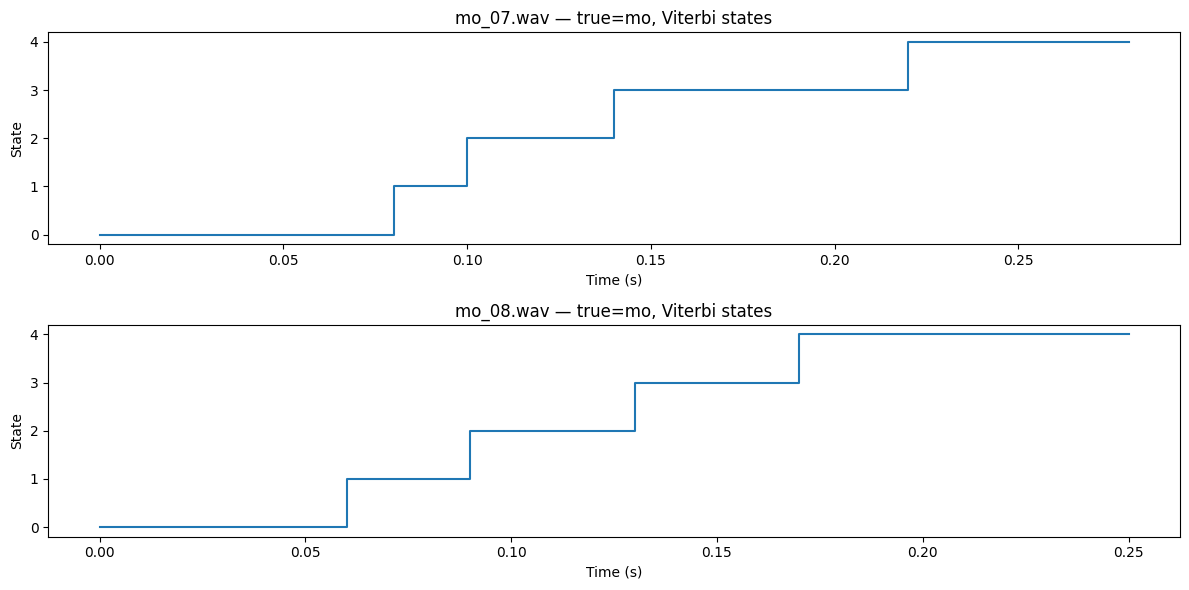

In [7]:
examples = test_meta.head(2)
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 3*len(examples)), squeeze=False)
for ax, (_, row) in zip(axes[:,0], examples.iterrows()):
    F = features[row.filename]
    state_path = models[row.label_code].predict(F)
    t = np.arange(len(F)) * HOP_LENGTH / SAMPLE_RATE
    ax.step(t, state_path, where="post"); ax.set_yticks(range(N_STATES))
    ax.set_title(f"{row.filename} — true={row.label_code}, Viterbi states")
    ax.set_xlabel("Time (s)"); ax.set_ylabel("State")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "viterbi_paths.png", dpi=160, bbox_inches="tight"); plt.show()


## Task 7 — Confusion matrix và báo cáo accuracy
Vì test chỉ có 2 mẫu mỗi lớp, accuracy thay đổi theo bước 10%; hãy diễn giải kết quả thận trọng.


Accuracy: 1.0
              precision    recall  f1-score   support

        đóng       1.00      1.00      1.00         2
        dừng       1.00      1.00      1.00         2
         lên       1.00      1.00      1.00         2
          mở       1.00      1.00      1.00         2
       xuống       1.00      1.00      1.00         2

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



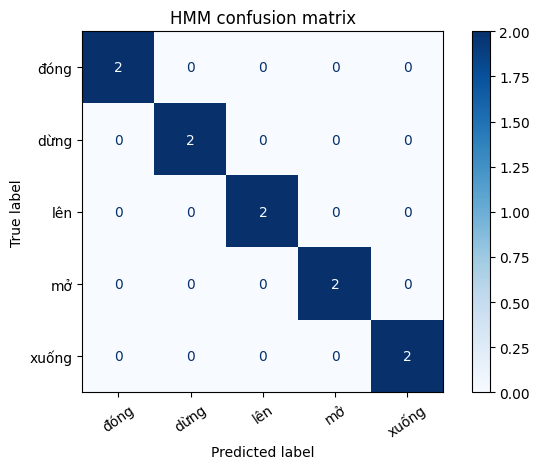

In [8]:
y_true, y_pred = results.true.tolist(), results.pred.tolist()
print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, labels=LABELS, target_names=[DISPLAY_NAMES[x] for x in LABELS], zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
ConfusionMatrixDisplay(cm, display_labels=[DISPLAY_NAMES[x] for x in LABELS]).plot(cmap="Blues", values_format="d", xticks_rotation=35)
plt.title("HMM confusion matrix"); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight"); plt.show()


## Task 8 — So sánh baseline DTW và HMM
DTW so sánh chuỗi MFCC bằng khoảng cách Euclidean theo đường warping; HMM score là log-likelihood tổng. Thời gian đo trên cùng máy chỉ mang tính tham khảo. Không so sánh trực tiếp độ lớn raw score giữa hai thuật toán.


In [9]:
def dtw_distance(A, B):
    # Dynamic programming memory O(len(B)); cost is mean Euclidean frame distance.
    prev = np.full(len(B)+1, np.inf); prev[0] = 0.0
    for a in A:
        cur = np.full(len(B)+1, np.inf)
        for j, b in enumerate(B, start=1):
            cost = np.linalg.norm(a-b)
            cur[j] = cost + min(cur[j-1], prev[j], prev[j-1])
        prev = cur
    return prev[-1] / (len(A)+len(B))

# Template: từng train utterance; chọn class có DTW distance nhỏ nhất trên mọi template.
dtw_times, dtw_preds = [], []
for _, row in test_meta.iterrows():
    F = features[row.filename]; t0=time.perf_counter()
    dist = {label: min(dtw_distance(F, features[r.filename])
                       for _, r in train_meta[train_meta.label_code == label].iterrows()) for label in LABELS}
    dtw_times.append(time.perf_counter()-t0); dtw_preds.append(min(dist, key=dist.get))
hmm_times=[]
for _, row in test_meta.iterrows():
    t0=time.perf_counter(); recognize(features[row.filename]); hmm_times.append(time.perf_counter()-t0)
comparison = pd.DataFrame({"model":["DTW","HMM"],
 "accuracy":[accuracy_score(y_true,dtw_preds), accuracy_score(y_true,y_pred)],
 "mean_test_seconds":[np.mean(dtw_times),np.mean(hmm_times)],
 "mean_train_seconds":[np.nan,np.mean(list(train_seconds.values()))]})
display(comparison)
comparison.to_csv(OUTPUT_DIR / "dtw_vs_hmm.csv", index=False)


,model,accuracy,mean_test_seconds,mean_train_seconds
0,DTW,1.0,0.096349,NaN
1,HMM,1.0,0.001048,0.012713


## Task 9 — Bigram language model re-ranking
Corpus starter chỉ có từng nhãn đơn lẻ, nên không thể ước lượng bigram đáng tin cậy. Cell dưới tạo bigram có smoothing từ danh sách câu lệnh do người dùng cung cấp; để `COMMAND_CORPUS` trống thì kết quả acoustic được giữ nguyên. `lm_weight` nên được chọn trên validation set nếu có.


In [10]:
from collections import Counter
import math
# Thêm danh sách câu lệnh thực tế nếu được cung cấp (mỗi phần tử là chuỗi label_code).
COMMAND_CORPUS = []  # ví dụ: [["mo"], ["dong"], ["mo", "dong"]]
LM_WEIGHT = 0.3
K_SMOOTH = 0.5

def fit_bigram(corpus, labels, k=K_SMOOTH):
    c1, c2 = Counter(), Counter()
    for sent in corpus:
        seq = ["<s>"] + list(sent) + ["</s>"]
        c1.update(seq[:-1]); c2.update(zip(seq[:-1], seq[1:]))
    vocab = len(labels)+1
    def logp(prev, cur):
        return math.log((c2[(prev,cur)]+k)/(c1[prev]+k*vocab))
    return logp

def rerank_single(scores, labels, log_bigram, lm_weight=LM_WEIGHT):
    # Một utterance đơn lẻ: dùng prior start -> label; cần sequence decoder cho lệnh nối tiếp.
    return max(labels, key=lambda w: scores[w] + lm_weight*log_bigram("<s>", w))

if COMMAND_CORPUS:
    log_bigram = fit_bigram(COMMAND_CORPUS, LABELS)
    lm_pred = [rerank_single(acoustic_scores(features[r.filename]), LABELS, log_bigram) for _,r in test_meta.iterrows()]
    print("Acoustic accuracy:", accuracy_score(y_true,y_pred), "| Bigram rerank accuracy:", accuracy_score(y_true,lm_pred))
else:
    print("Bỏ qua re-ranking: cần corpus lệnh/bigram; không tự tạo prior từ nhãn test.")


Bỏ qua re-ranking: cần corpus lệnh/bigram; không tự tạo prior từ nhãn test.


## Task 10 — Thí nghiệm gợi ý và câu hỏi thảo luận

### Trả lời câu hỏi thảo luận

**1. Forward và Viterbi khác nhau thế nào?** Forward cộng xác suất của mọi state path có thể sinh ra chuỗi quan sát, nên tính log P(X|W). Viterbi chỉ chọn state path có xác suất lớn nhất và trả về alignment tương ứng. Dùng Forward likelihood để so sánh các mô hình từ; dùng Viterbi để xem cách các frame được gán vào state. Hai thuật toán tối ưu hai đại lượng khác nhau.

**2. Vì sao Baum–Welch có thể hội tụ kém khi dữ liệu ít?** (i) Quá ít frame khiến ước lượng transition và emission nhiễu, hoặc covariance bị suy biến; (ii) EM có thể dừng ở cực đại cục bộ và phụ thuộc khởi tạo; (iii) một số state nhận quá ít quan sát, nhất là khi độ dài utterance khác nhau; (iv) quá nhiều state hoặc full covariance dễ gây overfit. Có thể giảm số state, dùng covariance diagonal, khởi tạo có cấu trúc, regularize covariance và thu thêm utterance độc lập.

**3. Delta features có ích gì?** MFCC tĩnh mô tả phổ tại một frame. Delta và delta-delta xấp xỉ vận tốc và gia tốc của đặc trưng theo thời gian, giúp biểu diễn chuyển tiếp âm học và động học tiếng nói. Chúng tăng số chiều từ 13 lên 39, do đó cũng làm tăng lượng dữ liệu cần để ước lượng mô hình.

**4. Whole-word HMM có thể ghép thành câu không? Khi nào cần lexicon/subword?** Có thể ghép các whole-word HMM bằng cách nối mô hình từ, nhưng cần lexicon và language model để giới hạn chuỗi. Whole-word HMM không nhận được từ chưa thấy nếu không có dữ liệu huấn luyện cho từ đó. Phone/subword HMM chia sẻ đơn vị giữa các từ, phù hợp hơn với từ vựng lớn hoặc từ ngoài từ điển. Với năm lệnh cô lập trong lab này, whole-word HMM là baseline hợp lý.

**5. Self-loop và đường đi Viterbi/DTW biểu thị gì?** Self-loop cho phép một state phát nhiều frame, nhờ đó mô hình hóa thời lượng biến đổi. Viterbi căn chỉnh frame với state trong HMM đã huấn luyện dựa trên xác suất chuyển và emission. DTW căn chỉnh trực tiếp hai chuỗi đặc trưng để giảm tổng khoảng cách. Cả hai cho phép co giãn thời gian, nhưng cách tính chi phí và ràng buộc khác nhau.

**6. Khi nào language model giúp hoặc làm sai?** Language model giúp khi các lựa chọn âm học gần nhau nhưng xác suất chuỗi trong ngôn ngữ khác nhau, và corpus LM phù hợp miền sử dụng. Nó có thể làm sai nếu corpus nhỏ/lệch miền hoặc trọng số LM lấn át bằng chứng âm học. Metadata hiện chỉ chứa lệnh đơn, không có chuỗi lệnh để học bigram đáng tin cậy; không tạo bigram từ nhãn test. HMM score là log-likelihood phụ thuộc độ dài chuỗi, còn DTW là khoảng cách (càng nhỏ càng tốt), nên không so sánh trực tiếp raw score của hai phương pháp.

**7. Vì sao argmax luôn chọn lớp? Làm sao từ chối từ ngoài từ vựng?** Argmax trên tập nhãn hữu hạn luôn trả về lớp có score cao nhất, kể cả khi tất cả score đều thấp. Có thể thêm ngưỡng reject dựa trên log-likelihood chuẩn hóa theo frame, khoảng cách top-1/top-2, hoặc mô hình unknown/silence được huấn luyện riêng. Chọn ngưỡng trên validation set, không chọn theo test.

### Thử nghiệm và giới hạn kết quả

Thử số state 3, 5, 7 và covariance diag, full; ghi accuracy train/test, thời gian train/test và likelihood. Bộ test chỉ có 10 file (hai file mỗi lớp), nên accuracy đổi theo bước 10 điểm phần trăm và chưa đủ để kết luận chắc chắn. Cần dùng validation set độc lập để chọn tham số. Dataset eSpeak tổng hợp này không đại diện cho tiếng nói người hoặc khả năng hoạt động trong môi trường thực.


## Task 11 — Lưu artifacts tùy chọn
Việc tuần tự hóa model không bắt buộc. Nếu cần, lưu các mô hình cùng scaler trong `artifacts/` và thêm thư mục này vào `.gitignore` nếu không muốn commit file nhị phân.


In [11]:
# import joblib
# artifact_dir = NOTEBOOK_DIR / "artifacts"
# artifact_dir.mkdir(exist_ok=True)
# joblib.dump({"models":models, "labels":LABELS, "mean":feat_mean, "std":feat_std}, artifact_dir/"hmm_models.joblib")
